# Sloan Digital Sky Survey (SDSS): Stellar Object Classification
## Pattern Recognition Semester Project — Variant 2: Color Feature Engineering

### 1. Astrophysical Motivation and Objective

In Phase 1 ([01_sdss_baseline_classification.ipynb](file:///c:/Users/chsan/OneDrive/Desktop/Stellar_Classification/01_sdss_baseline_classification.ipynb)), we established baseline classification benchmarks using exclusively the five raw apparent photometric magnitudes ($u, g, r, i, z$) on ~100,000 SDSS Data Release 17 observations. While non-linear baseline models achieved respectable accuracy (~86.5%), their primary bottleneck was discriminating between unresolved point sources (**Stars** and **Quasars**), as well as distinguishing faint, low-surface-brightness **Galaxies**.

#### The Physical Nature of Astronomical Color Indices
In observational astronomy, the apparent magnitude $m_\lambda$ measured through a photometric filter centered at wavelength $\lambda$ is defined logarithmically by Pogson's relation:
$$m_\lambda = -2.5 \log_{10}\left(\frac{F_\lambda}{F_{\lambda, 0}}\right)$$

where $F_\lambda$ is the observed monochromatic flux density and $F_{\lambda, 0}$ is the zero-point flux reference.

According to the inverse-square law of radiation, observed flux decreases with the square of the distance $d$ to the celestial object:
$$F_\lambda = \frac{L_\lambda}{4 \pi d^2}$$

where $L_\lambda$ is intrinsic luminosity. Consequently, **raw apparent magnitudes depend conflatedly on both intrinsic luminosity and distance**. A nearby cool dwarf star and a distant hyper-luminous quasar can yield virtually identical apparent magnitudes across broadband filters.

When we compute an **astronomical color index** as the difference between two filter magnitudes:
$$c_{12} = m_1 - m_2 = -2.5 \log_{10}\left(\frac{F_1}{F_2}\right) + \text{constant}$$

The distance term $d^2$ **cancels out completely**! The color index represents the logarithm of the flux ratio across two spectral regimes. Color indices are therefore **distance-independent physical observables** that directly trace:
1. **Effective Surface Temperature**: Governed by Planck's law of blackbody radiation and Wien's displacement law.
2. **Spectral Continuum Slope**: Revealing thermal versus non-thermal power-law emission.
3. **Absorption and Emission Line Signatures**: Capturing the Balmer discontinuity, metallic absorption lines, and quasar emission features.

#### The Four Engineered Color Features
We engineer four adjacent color indices from the SDSS filter system:
- **`u_g = u - g`**: Ultraviolet-to-green slope. Highly sensitive to hot stellar photospheres, the Balmer jump (364.6 nm), and the UV excess characteristic of active accretion disks in quasars.
- **`g_r = g - r`**: Optical slope. Strongly correlates with stellar spectral types (O/B/A hot blue stars vs. G/K/M cool red stars) and galaxy stellar population age.
- **`r_i = r - i`**: Red-to-near-infrared slope. Key discriminator for cool low-mass M-dwarfs, giant stars, and dusty early-type galaxies.
- **`i_z = i - z`**: Near-infrared slope. Traces late-type stars, substellar brown dwarfs, and high-redshift quasar continuum reddening.

#### Objective and Research Questions
We conduct a rigorous, controlled experiment comparing two configurations under the **identical train/test split**:
1. **Configuration 1 (Original Features):** `u`, `g`, `r`, `i`, `z` (5 features)
2. **Configuration 2 (Original + Color Features):** `u`, `g`, `r`, `i`, `z`, `u_g`, `g_r`, `r_i`, `i_z` (9 features)

**Core Research Questions:**
1. *Do astronomical color indices improve multiclass classification metrics over the raw 5-band baseline?*
2. *Which machine learning model architectures (linear vs. instance-based vs. tree-based) benefit from explicit color features, and what are the mathematical principles explaining this behavior?*
3. *Which astronomical classes (`STAR`, `GALAXY`, `QSO`) exhibit the greatest reduction in classification error?*

## 2. Imports and Configuration

We configure the scientific environment using:
- `pandas` and `numpy` for data manipulation, array operations, and feature transformations.
- `matplotlib.pyplot` and `seaborn` for publication-quality scientific visualization.
- `scikit-learn` for train/test splitting, explicit feature standardization, baseline estimators, and multiclass metrics.
- `RANDOM_SEED = 42` for end-to-end experimental reproducibility.
- `DATA_PATH` configured centrally for seamless local and Google Colab execution.

In [3]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Scikit-learn tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# -----------------------------------------------------------------------------
# Global Reproducibility Seed
# -----------------------------------------------------------------------------
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# -----------------------------------------------------------------------------
# Visualization Styling
# -----------------------------------------------------------------------------
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

CLASS_PALETTE = {
    'GALAXY': '#3470a3',
    'STAR': '#2ca02c',
    'QSO': '#d62728'
}
sns.set_palette(list(CLASS_PALETTE.values()))

# -----------------------------------------------------------------------------
# Dataset Path Configuration
# - Local relative path: 'star_classification.csv'
# - Google Colab upload: '/content/star_classification.csv'
# - Google Drive mount:  '/content/drive/MyDrive/.../star_classification.csv'
# -----------------------------------------------------------------------------
DATA_PATH = 'star_classification.csv'

print(f"Dataset path configured: {DATA_PATH}")
print(f"Reproducibility random seed: {RANDOM_SEED}")

Dataset path configured: star_classification.csv
Reproducibility random seed: 42


## 3. Dataset Loading, Inspection, and Anomaly Handling

We load the SDSS Data Release 17 dataset and replicate the rigorous data hygiene established in Phase 1:
1. Verify the shape, schema, and data types.
2. Check for missing values and full-row duplicates.
3. Detect and explicitly remove unphysical sentinel values (`-9999.0` in photometric bands).
4. Inspect unique identifiers (`spec_obj_ID`, `obj_ID`) to evaluate potential train/test leakage.

In [4]:
# Load dataset
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found at '{DATA_PATH}'.\n"
        "Please upload 'star_classification.csv' or adjust DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
print(f"Dataset successfully loaded. Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns.\n")

# Missing values and duplicates audit
null_count = df.isnull().sum().sum()
exact_dupes = df.duplicated().sum()
print(f"Explicit NaN / null values found: {null_count}")
print(f"Exact full-row duplicate records: {exact_dupes}")

Dataset successfully loaded. Dimensions: 100,000 rows x 18 columns.

Explicit NaN / null values found: 0
Exact full-row duplicate records: 0


In [5]:
# Search for rows containing unphysical photometric sentinel values (< 0)
corrupt_mask = (df['u'] < 0) | (df['g'] < 0) | (df['r'] < 0) | (df['i'] < 0) | (df['z'] < 0)
corrupt_count = corrupt_mask.sum()
print(f"Number of rows with unphysical photometric sentinel values (< 0): {corrupt_count}")

if corrupt_count > 0:
    print("\nCorrupted observation details:")
    display(df[corrupt_mask][['obj_ID', 'u', 'g', 'r', 'i', 'z', 'class', 'redshift']])

    # Remove the single corrupted observation explicitly
    df_clean = df[~corrupt_mask].copy().reset_index(drop=True)
    print(f"\nRemoved {corrupt_count} corrupt row. Cleaned dataset: {df_clean.shape[0]:,} rows.")
else:
    df_clean = df.copy()

# Confirm zero NaN or infinite values remain in photometric features
assert not df_clean[['u', 'g', 'r', 'i', 'z']].isnull().any().any(), "Unexpected NaNs remain!"
assert not np.isinf(df_clean[['u', 'g', 'r', 'i', 'z']].values).any(), "Unexpected Inf values remain!"

Number of rows with unphysical photometric sentinel values (< 0): 1

Corrupted observation details:


,obj_ID,u,g,r,i,z,class,redshift
79543,1.237649e+18,-9999.0,-9999.0,18.1656,18.01675,-9999.0,STAR,0.000089



Removed 1 corrupt row. Cleaned dataset: 99,999 rows.


In [6]:
print("=" * 70)
print("IDENTIFIER UNIQUENESS AND DUPLICATE AUDIT")
print("=" * 70)

total_rows = len(df_clean)
unique_spec = df_clean['spec_obj_ID'].nunique()
unique_obj = df_clean['obj_ID'].nunique()
unique_coords = df_clean[['alpha', 'delta']].drop_duplicates().shape[0]

print(f"Total cleaned observations:                     {total_rows:,}")
print(f"Unique spectroscopic IDs (spec_obj_ID):         {unique_spec:,} (Duplicates: {total_rows - unique_spec})")
print(f"Unique photometric detection IDs (obj_ID):      {unique_obj:,} (Repeated exposures: {total_rows - unique_obj})")
print(f"Unique celestial coordinates (alpha, delta):    {unique_coords:,} (Overlapping points: {total_rows - unique_coords})")

print("\nAudit summary:")
print(f"- All {total_rows:,} records possess completely unique spectroscopic IDs (spec_obj_ID).")
print("- Each record corresponds to an independently calibrated spectroscopic observation.")
print("- Repeated obj_ID records reflect multi-epoch photometric exposures and are preserved without leakage.")

IDENTIFIER UNIQUENESS AND DUPLICATE AUDIT
Total cleaned observations:                     99,999
Unique spectroscopic IDs (spec_obj_ID):         99,999 (Duplicates: 0)
Unique photometric detection IDs (obj_ID):      78,052 (Repeated exposures: 21947)
Unique celestial coordinates (alpha, delta):    99,998 (Overlapping points: 1)

Audit summary:
- All 99,999 records possess completely unique spectroscopic IDs (spec_obj_ID).
- Each record corresponds to an independently calibrated spectroscopic observation.
- Repeated obj_ID records reflect multi-epoch photometric exposures and are preserved without leakage.


## 4. Astronomical Color Feature Engineering

We construct the four adjacent color indices by computing logarithmic flux differences:
- `u_g = u - g`
- `g_r = g - r`
- `r_i = r - i`
- `i_z = i - z`

We then conduct targeted exploratory data analysis to evaluate their statistical distributions and astrophysical discriminative power.

In [7]:
# Engineer astronomical color indices
df_clean['u_g'] = df_clean['u'] - df_clean['g']
df_clean['g_r'] = df_clean['g'] - df_clean['r']
df_clean['r_i'] = df_clean['r'] - df_clean['i']
df_clean['i_z'] = df_clean['i'] - df_clean['z']

COLOR_COLS = ['u_g', 'g_r', 'r_i', 'i_z']

print("Summary Statistics of Engineered Color Indices:")
display(df_clean[COLOR_COLS].describe().round(4))

Summary Statistics of Engineered Color Indices:


,u_g,g_r,r_i,i_z
count,99999.0000,99999.0000,99999.0000,99999.0000
mean,1.4491,0.9858,0.5609,0.3159
std,1.1793,0.7347,0.5015,0.4204
min,-12.7481,-12.3186,-14.6491,-13.1625
25%,0.6312,0.3798,0.2163,0.1345
50%,1.3217,0.9315,0.4798,0.3380
75%,2.0446,1.5780,0.8922,0.4741
max,18.6250,14.3152,12.2058,13.4271


### 4.1 Distributions of Engineered Color Features
We plot histograms with Kernel Density Estimates (KDE) for the four color indices. To provide interpretable physical visualizations unskewed by faint extreme photometric noise tails, distributions are displayed between the 0.5th and 99.5th percentiles.

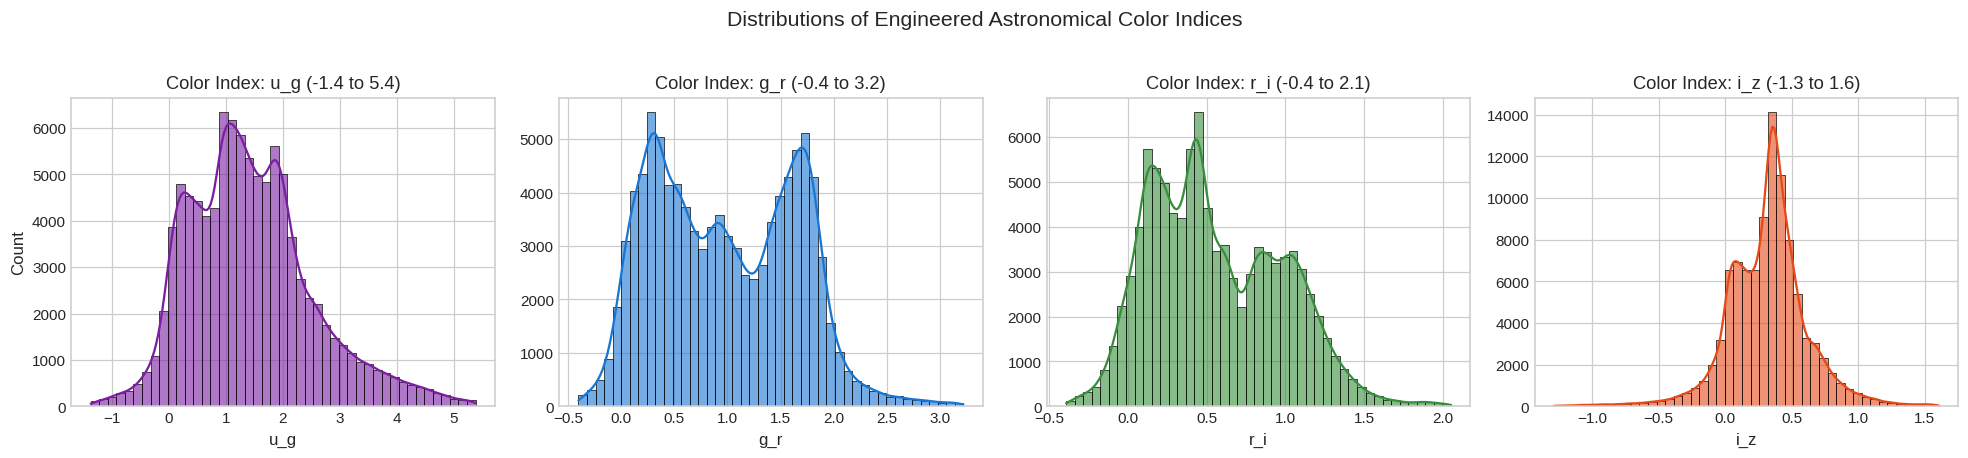

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
color_palette_list = ['#7b1fa2', '#1976d2', '#388e3c', '#e64a19']

for idx, (col, c_color) in enumerate(zip(COLOR_COLS, color_palette_list)):
    ax = axes[idx]
    # Filter between 0.5th and 99.5th percentiles for clear physical display
    p_low, p_high = df_clean[col].quantile(0.005), df_clean[col].quantile(0.995)
    filtered_series = df_clean[(df_clean[col] >= p_low) & (df_clean[col] <= p_high)][col]

    sns.histplot(filtered_series, kde=True, ax=ax, color=c_color, bins=45, edgecolor='black', alpha=0.6)
    ax.set_title(f"Color Index: {col} ({p_low:.1f} to {p_high:.1f})")
    ax.set_xlabel(col)
    ax.set_ylabel("Count" if idx == 0 else "")

plt.suptitle("Distributions of Engineered Astronomical Color Indices", fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

### 4.2 Astrophysical Color-Color Diagrams
In observational astronomy, **color-color diagrams** are among the most powerful diagnostic tools available:
- **$(u-g)$ vs. $(g-r)$ Diagram**: Main-sequence stars form a characteristic, tight curved track known as the **stellar locus**. Quasars populate a distinct region characterized by significant ultraviolet excess ($u-g \lesssim 0.6$) due to non-thermal synchrotron/accretion disk emission.
- **$(g-r)$ vs. $(r-i)$ Diagram**: Separates early-type galaxies (redder optical colors due to old stellar populations and dust) from bluer star-forming systems and stellar sequences.

/tmp/ipykernel_2671/577424824.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sample_df = df_clean.groupby('class', group_keys=False).apply(


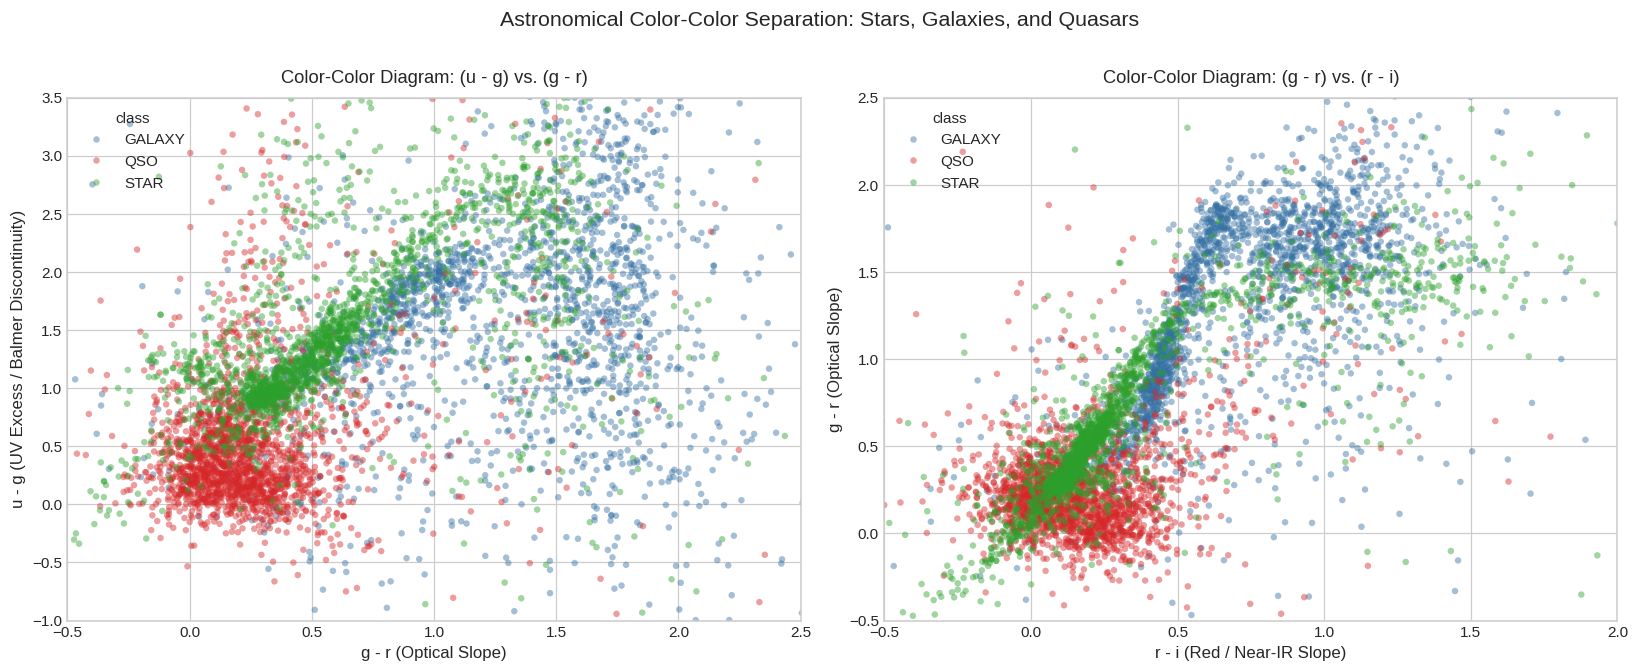

In [9]:
# Sample 6,000 points (2,000 per class) for a clear, responsive scatter visualization
sample_df = df_clean.groupby('class', group_keys=False).apply(
    lambda grp: grp.sample(n=min(len(grp), 2000), random_state=RANDOM_SEED)
).reset_index(drop=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: (u-g) vs (g-r)
sns.scatterplot(
    data=sample_df,
    x='g_r',
    y='u_g',
    hue='class',
    palette=CLASS_PALETTE,
    alpha=0.45,
    s=18,
    edgecolor='none',
    ax=ax1
)
ax1.set_xlim(-0.5, 2.5)
ax1.set_ylim(-1.0, 3.5)
ax1.set_title("Color-Color Diagram: (u - g) vs. (g - r)", pad=10)
ax1.set_xlabel("g - r (Optical Slope)")
ax1.set_ylabel("u - g (UV Excess / Balmer Discontinuity)")

# Plot 2: (g-r) vs (r-i)
sns.scatterplot(
    data=sample_df,
    x='r_i',
    y='g_r',
    hue='class',
    palette=CLASS_PALETTE,
    alpha=0.45,
    s=18,
    edgecolor='none',
    ax=ax2
)
ax2.set_xlim(-0.5, 2.0)
ax2.set_ylim(-0.5, 2.5)
ax2.set_title("Color-Color Diagram: (g - r) vs. (r - i)", pad=10)
ax2.set_xlabel("r - i (Red / Near-IR Slope)")
ax2.set_ylabel("g - r (Optical Slope)")

plt.suptitle("Astronomical Color-Color Separation: Stars, Galaxies, and Quasars", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### 4.3 Color Indices Grouped by Astronomical Class
We analyze the distribution of each color index across Stars, Galaxies, and Quasars using boxplots.

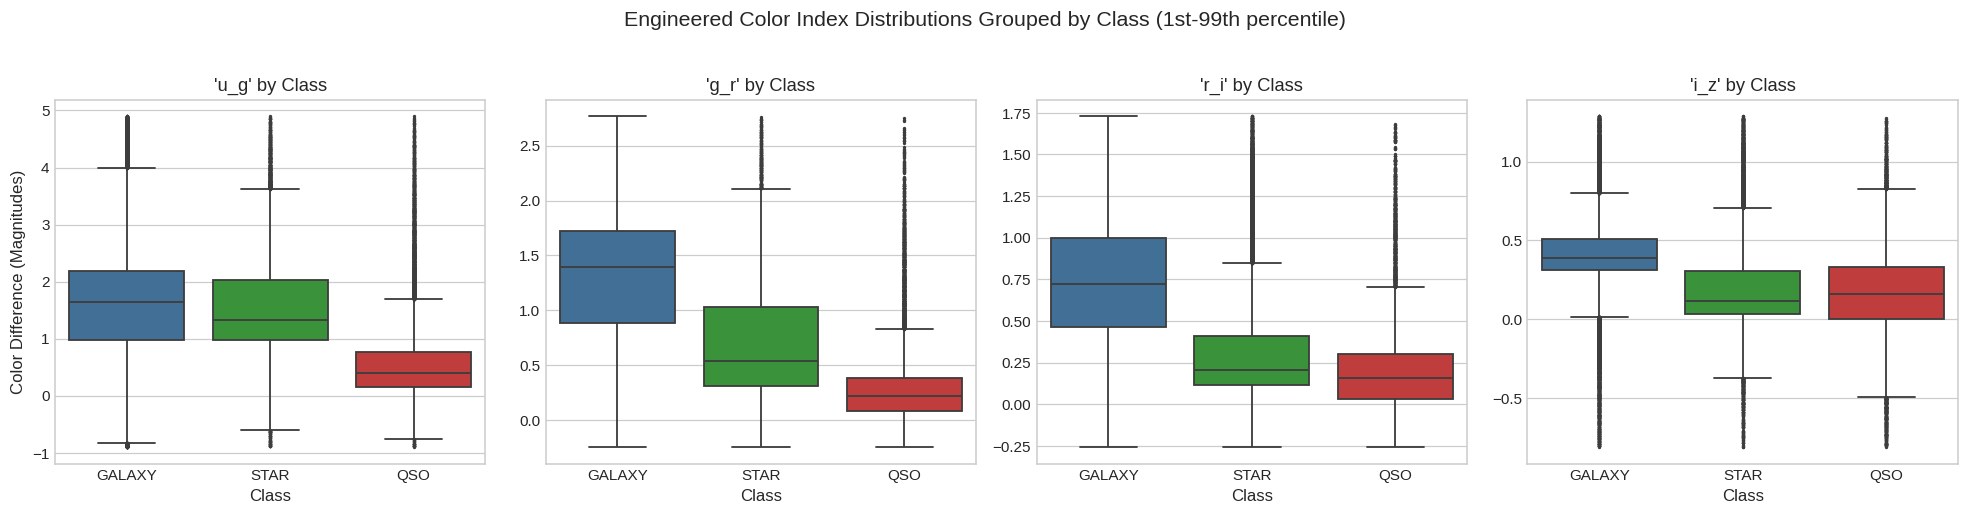

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
class_order = ['GALAXY', 'STAR', 'QSO']

for idx, col in enumerate(COLOR_COLS):
    # Filter extreme outliers for clear boxplot presentation
    p_low, p_high = df_clean[col].quantile(0.01), df_clean[col].quantile(0.99)
    df_box = df_clean[(df_clean[col] >= p_low) & (df_clean[col] <= p_high)]

    sns.boxplot(
        data=df_box,
        x='class',
        y=col,
        hue='class',
        order=class_order,
        palette=CLASS_PALETTE,
        legend=False,
        ax=axes[idx],
        fliersize=1.2,
        linewidth=1.2
    )
    axes[idx].set_title(f"'{col}' by Class")
    axes[idx].set_xlabel("Class")
    axes[idx].set_ylabel("Color Difference (Magnitudes)" if idx == 0 else "")

plt.suptitle("Engineered Color Index Distributions Grouped by Class (1st-99th percentile)", fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

### 4.4 Correlation Heatmap: Original vs. Engineered Color Features
We compute the correlation matrix across all 9 features ($u, g, r, i, z, u\_g, g\_r, r\_i, i\_z$). Notice that while adjacent raw magnitudes are heavily collinear ($r \sim 0.90 - 0.97$), color indices have much lower mutual collinearity and capture orthogonal spectral gradient information.

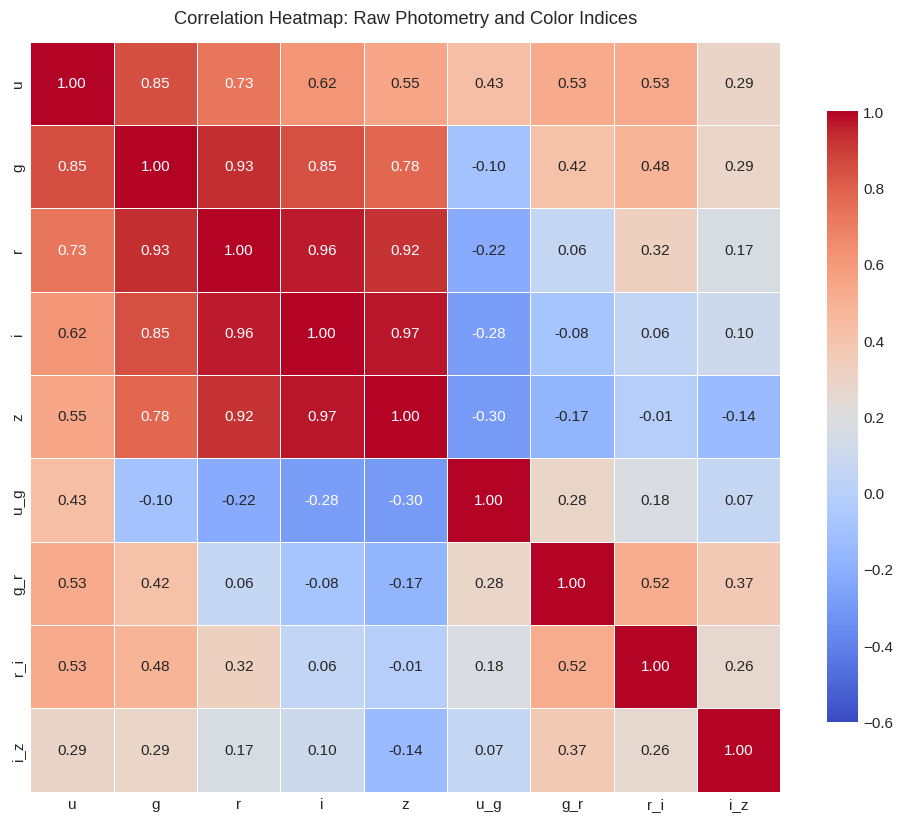

In [11]:
all_features = ['u', 'g', 'r', 'i', 'z', 'u_g', 'g_r', 'r_i', 'i_z']
corr_mat = df_clean[all_features].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(
    corr_mat,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    vmin=-0.6,
    vmax=1.0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8},
    ax=ax
)
ax.set_title("Correlation Heatmap: Raw Photometry and Color Indices", pad=12)
plt.tight_layout()
plt.show()

## 5. Feature Sets Definition and Leakage-Free Train/Test Split

### 5.1 Defining the Experimental Configurations
To isolate the exact causal impact of color feature engineering, we evaluate two feature matrices:
1. **Configuration 1 (Original Features):** `['u', 'g', 'r', 'i', 'z']` (5 features)
2. **Configuration 2 (Original + Color Features):** `['u', 'g', 'r', 'i', 'z', 'u_g', 'g_r', 'r_i', 'i_z']` (9 features)

**Feature Exclusions Maintained**:
- Target variable `class` separated into target vector $y$.
- Administrative keys and metadata (`obj_ID`, `spec_obj_ID`, `run_ID`, `rerun_ID`, `cam_col`, `field_ID`, `plate`, `MJD`, `fiber_ID`) excluded.
- Celestial coordinates (`alpha`, `delta`) excluded to avoid spatial memorization.
- Spectroscopic `redshift` excluded to evaluate pure optical photometric performance.

### 5.2 Strict Leakage-Free Split and Preprocessing Hygiene
- **Identical Split**: We apply stratified 80/20 partitioning with `RANDOM_SEED = 42` and `stratify=y`. Because the partition index is identical to Phase 1, the test set is completely held-out and directly comparable.
- **Independent Scalers**:
  - `scaler_orig`: Fit **strictly on `X_train_orig`**, used to transform `X_train_orig` and `X_test_orig`.
  - `scaler_color`: Fit **strictly on `X_train_color`**, used to transform `X_train_color` and `X_test_color`.
  - Zero test-set distribution statistics leak into training.
- Per project rules, no scikit-learn `Pipeline` objects are used.

In [12]:
# Define feature subsets
ORIG_FEATURES = ['u', 'g', 'r', 'i', 'z']
COLOR_FEATURES = ['u', 'g', 'r', 'i', 'z', 'u_g', 'g_r', 'r_i', 'i_z']
TARGET_COLUMN = 'class'

X_orig_all = df_clean[ORIG_FEATURES].copy()
X_color_all = df_clean[COLOR_FEATURES].copy()
y = df_clean[TARGET_COLUMN].copy()

# Stratified 80/20 train/test split on original features
X_train_orig, X_test_orig, y_train, y_test = train_test_split(
    X_orig_all, y,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=y
)

# Extract identical split index for color features
X_train_color = X_color_all.loc[X_train_orig.index].copy()
X_test_color = X_color_all.loc[X_test_orig.index].copy()

print(f"Training observations: {X_train_orig.shape[0]:,} (80%)")
print(f"Test observations:     {X_test_orig.shape[0]:,} (20%)")
print(f"Original feature set shape:  {X_train_orig.shape}")
print(f"Color feature set shape:     {X_train_color.shape}\n")

# Verify stratification consistency
strat_table = pd.DataFrame({
    'Train Count': y_train.value_counts(),
    'Train (%)': (y_train.value_counts(normalize=True) * 100).round(2),
    'Test Count': y_test.value_counts(),
    'Test (%)': (y_test.value_counts(normalize=True) * 100).round(2)
})
print("Stratification Verification Across Splits:")
display(strat_table)

Training observations: 79,999 (80%)
Test observations:     20,000 (20%)
Original feature set shape:  (79999, 5)
Color feature set shape:     (79999, 9)

Stratification Verification Across Splits:


,Train Count,Train (%),Test Count,Test (%)
class,,,,
GALAXY,47556,59.45,11889,59.44
STAR,17274,21.59,4319,21.60
QSO,15169,18.96,3792,18.96


In [13]:
# Fit standardizers strictly on training partitions
scaler_orig = StandardScaler()
X_train_orig_scaled = scaler_orig.fit_transform(X_train_orig)
X_test_orig_scaled = scaler_orig.transform(X_test_orig)

scaler_color = StandardScaler()
X_train_color_scaled = scaler_color.fit_transform(X_train_color)
X_test_color_scaled = scaler_color.transform(X_test_color)

# Verification of scaling hygiene (zero mean, unit variance on train)
print("StandardScaler Check for Color Feature Set (Train vs Test):")
scaling_check = pd.DataFrame({
    'Train Mean': X_train_color_scaled.mean(axis=0).round(4),
    'Train Std':  X_train_color_scaled.std(axis=0).round(4),
    'Test Mean':  X_test_color_scaled.mean(axis=0).round(4),
    'Test Std':   X_test_color_scaled.std(axis=0).round(4)
}, index=COLOR_FEATURES)
display(scaling_check)

StandardScaler Check for Color Feature Set (Train vs Test):


,Train Mean,Train Std,Test Mean,Test Std
u,0.0,1.0,0.0153,1.0053
g,-0.0,1.0,0.0090,0.9968
r,0.0,1.0,0.0043,0.9953
i,0.0,1.0,0.0040,0.9976
z,-0.0,1.0,0.0005,0.9962
u_g,0.0,1.0,0.0138,1.0113
g_r,0.0,1.0,0.0139,0.9882
r_i,-0.0,1.0,0.0018,0.9913
i_z,0.0,1.0,0.0147,0.9766


## 6. Model Training Across Both Configurations

We train and evaluate all four baseline classifiers across both feature configurations:
1. **Multinomial Logistic Regression** (`max_iter=1000`, `random_state=42`, standardized inputs)
2. **K-Nearest Neighbors (KNN)** ($k=5$, Euclidean distance, `n_jobs=-1`, standardized inputs)
3. **Linear Support Vector Machine (Linear SVM)** (`LinearSVC`, `dual='auto'`, `max_iter=2000`, `random_state=42`, standardized inputs)
4. **Random Forest Classifier** (`n_estimators=100`, `max_depth=15`, `min_samples_split=5`, `random_state=42`, `n_jobs=-1`, unscaled inputs)

We record execution times for each training and inference pass to measure computational trade-offs.

In [14]:
print("=" * 70)
print("EXPERIMENT 1: LOGISTIC REGRESSION")
print("=" * 70)

# 1. Original features
lr_orig = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)
t0 = time.time()
lr_orig.fit(X_train_orig_scaled, y_train)
lr_orig_t_train = time.time() - t0
t1 = time.time()
lr_orig_preds = lr_orig.predict(X_test_orig_scaled)
lr_orig_t_pred = time.time() - t1

# 2. Original + Color features
lr_color = LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)
t0 = time.time()
lr_color.fit(X_train_color_scaled, y_train)
lr_color_t_train = time.time() - t0
t1 = time.time()
lr_color_preds = lr_color.predict(X_test_color_scaled)
lr_color_t_pred = time.time() - t1

print(f"Orig Features  -> Train Time: {lr_orig_t_train:.2f}s | Predict Time: {lr_orig_t_pred:.3f}s")
print(f"Color Features -> Train Time: {lr_color_t_train:.2f}s | Predict Time: {lr_color_t_pred:.3f}s")

EXPERIMENT 1: LOGISTIC REGRESSION
Orig Features  -> Train Time: 1.30s | Predict Time: 0.002s
Color Features -> Train Time: 0.71s | Predict Time: 0.002s


In [15]:
print("=" * 70)
print("EXPERIMENT 2: K-NEAREST NEIGHBORS (KNN, k=5)")
print("=" * 70)

# 1. Original features
knn_orig = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
t0 = time.time()
knn_orig.fit(X_train_orig_scaled, y_train)
knn_orig_t_train = time.time() - t0
t1 = time.time()
knn_orig_preds = knn_orig.predict(X_test_orig_scaled)
knn_orig_t_pred = time.time() - t1

# 2. Original + Color features
knn_color = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
t0 = time.time()
knn_color.fit(X_train_color_scaled, y_train)
knn_color_t_train = time.time() - t0
t1 = time.time()
knn_color_preds = knn_color.predict(X_test_color_scaled)
knn_color_t_pred = time.time() - t1

print(f"Orig Features  -> Train Time: {knn_orig_t_train:.2f}s | Predict Time: {knn_orig_t_pred:.2f}s")
print(f"Color Features -> Train Time: {knn_color_t_train:.2f}s | Predict Time: {knn_color_t_pred:.2f}s")

EXPERIMENT 2: K-NEAREST NEIGHBORS (KNN, k=5)
Orig Features  -> Train Time: 0.24s | Predict Time: 0.26s
Color Features -> Train Time: 0.22s | Predict Time: 0.56s


In [16]:
print("=" * 70)
print("EXPERIMENT 3: LINEAR SUPPORT VECTOR MACHINE (LinearSVC)")
print("=" * 70)

# 1. Original features
svm_orig = LinearSVC(random_state=RANDOM_SEED, max_iter=2000, dual='auto')
t0 = time.time()
svm_orig.fit(X_train_orig_scaled, y_train)
svm_orig_t_train = time.time() - t0
t1 = time.time()
svm_orig_preds = svm_orig.predict(X_test_orig_scaled)
svm_orig_t_pred = time.time() - t1

# 2. Original + Color features
svm_color = LinearSVC(random_state=RANDOM_SEED, max_iter=2000, dual='auto')
t0 = time.time()
svm_color.fit(X_train_color_scaled, y_train)
svm_color_t_train = time.time() - t0
t1 = time.time()
svm_color_preds = svm_color.predict(X_test_color_scaled)
svm_color_t_pred = time.time() - t1

print(f"Orig Features  -> Train Time: {svm_orig_t_train:.2f}s | Predict Time: {svm_orig_t_pred:.3f}s")
print(f"Color Features -> Train Time: {svm_color_t_train:.2f}s | Predict Time: {svm_color_t_pred:.3f}s")

EXPERIMENT 3: LINEAR SUPPORT VECTOR MACHINE (LinearSVC)
Orig Features  -> Train Time: 0.31s | Predict Time: 0.001s
Color Features -> Train Time: 0.34s | Predict Time: 0.002s


In [17]:
print("=" * 70)
print("EXPERIMENT 4: RANDOM FOREST CLASSIFIER (100 Trees)")
print("=" * 70)

# 1. Original features
rf_orig = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    random_state=RANDOM_SEED,
    n_jobs=-1
)
t0 = time.time()
rf_orig.fit(X_train_orig, y_train)
rf_orig_t_train = time.time() - t0
t1 = time.time()
rf_orig_preds = rf_orig.predict(X_test_orig)
rf_orig_t_pred = time.time() - t1

# 2. Original + Color features
rf_color = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    random_state=RANDOM_SEED,
    n_jobs=-1
)
t0 = time.time()
rf_color.fit(X_train_color, y_train)
rf_color_t_train = time.time() - t0
t1 = time.time()
rf_color_preds = rf_color.predict(X_test_color)
rf_color_t_pred = time.time() - t1

print(f"Orig Features  -> Train Time: {rf_orig_t_train:.2f}s | Predict Time: {rf_orig_t_pred:.2f}s")
print(f"Color Features -> Train Time: {rf_color_t_train:.2f}s | Predict Time: {rf_color_t_pred:.2f}s")

EXPERIMENT 4: RANDOM FOREST CLASSIFIER (100 Trees)
Orig Features  -> Train Time: 19.95s | Predict Time: 0.19s
Color Features -> Train Time: 28.70s | Predict Time: 0.18s


## 7. Model Evaluation and Comprehensive Results Comparison

We systematically evaluate both configurations across all models using:
- Overall Accuracy
- Macro-averaged Precision, Recall, and F1-Score
- Per-class F1-scores for `GALAXY`, `STAR`, and `QSO`
- Net metric differences ($\Delta$) directly quantifying the effect of color features

In [18]:
class_labels = ['GALAXY', 'STAR', 'QSO']

model_predictions = {
    'Logistic Regression': (lr_orig_preds, lr_color_preds, lr_orig_t_train, lr_color_t_train),
    'K-Nearest Neighbors': (knn_orig_preds, knn_color_preds, knn_orig_t_train, knn_color_t_train),
    'Linear SVM':          (svm_orig_preds, svm_color_preds, svm_orig_t_train, svm_color_t_train),
    'Random Forest':       (rf_orig_preds, rf_color_preds, rf_orig_t_train, rf_color_t_train)
}

comparison_rows = []

for name, (p_orig, p_color, t_tr_o, t_tr_c) in model_predictions.items():
    # Orig metrics
    acc_o = accuracy_score(y_test, p_orig)
    f1_macro_o = f1_score(y_test, p_orig, average='macro', zero_division=0)
    p_macro_o = precision_score(y_test, p_orig, average='macro', zero_division=0)
    r_macro_o = recall_score(y_test, p_orig, average='macro', zero_division=0)
    per_f1_o = f1_score(y_test, p_orig, average=None, labels=class_labels, zero_division=0)

    # Color metrics
    acc_c = accuracy_score(y_test, p_color)
    f1_macro_c = f1_score(y_test, p_color, average='macro', zero_division=0)
    p_macro_c = precision_score(y_test, p_color, average='macro', zero_division=0)
    r_macro_c = recall_score(y_test, p_color, average='macro', zero_division=0)
    per_f1_c = f1_score(y_test, p_color, average=None, labels=class_labels, zero_division=0)

    comparison_rows.append({
        'Model': name,
        'Acc (Orig)': acc_o,
        'Acc (Color)': acc_c,
        'Δ Accuracy': acc_c - acc_o,
        'Macro F1 (Orig)': f1_macro_o,
        'Macro F1 (Color)': f1_macro_c,
        'Δ Macro F1': f1_macro_c - f1_macro_o,
        'F1_STAR (Orig)': per_f1_o[1],
        'F1_STAR (Color)': per_f1_c[1],
        'Δ F1_STAR': per_f1_c[1] - per_f1_o[1],
        'F1_QSO (Orig)': per_f1_o[2],
        'F1_QSO (Color)': per_f1_c[2],
        'Δ F1_QSO': per_f1_c[2] - per_f1_o[2],
        'F1_GAL (Orig)': per_f1_o[0],
        'F1_GAL (Color)': per_f1_c[0],
        'Δ F1_GAL': per_f1_c[0] - per_f1_o[0]
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values(by='Macro F1 (Color)', ascending=False).reset_index(drop=True)

print("=" * 110)
print("COMPREHENSIVE PERFORMANCE COMPARISON: ORIGINAL VS. COLOR-ENGINEERED FEATURES")
print("=" * 110)
display(comparison_df.style.format({
    'Acc (Orig)': '{:.4f}',
    'Acc (Color)': '{:.4f}',
    'Δ Accuracy': '{:+.4f}',
    'Macro F1 (Orig)': '{:.4f}',
    'Macro F1 (Color)': '{:.4f}',
    'Δ Macro F1': '{:+.4f}',
    'F1_STAR (Orig)': '{:.4f}',
    'F1_STAR (Color)': '{:.4f}',
    'Δ F1_STAR': '{:+.4f}',
    'F1_QSO (Orig)': '{:.4f}',
    'F1_QSO (Color)': '{:.4f}',
    'Δ F1_QSO': '{:+.4f}',
    'F1_GAL (Orig)': '{:.4f}',
    'F1_GAL (Color)': '{:.4f}',
    'Δ F1_GAL': '{:+.4f}'
}))

COMPREHENSIVE PERFORMANCE COMPARISON: ORIGINAL VS. COLOR-ENGINEERED FEATURES


,Model,Acc (Orig),Acc (Color),Δ Accuracy,Macro F1 (Orig),Macro F1 (Color),Δ Macro F1,F1_STAR (Orig),F1_STAR (Color),Δ F1_STAR,F1_QSO (Orig),F1_QSO (Color),Δ F1_QSO,F1_GAL (Orig),F1_GAL (Color),Δ F1_GAL
0,Random Forest,0.8656,0.8847,+0.0191,0.8277,0.8514,+0.0236,0.7557,0.8062,+0.0504,0.8083,0.8151,+0.0068,0.9192,0.9329,+0.0137
1,K-Nearest Neighbors,0.8625,0.8761,+0.0136,0.8244,0.8415,+0.0172,0.7640,0.7960,+0.0320,0.7912,0.8023,+0.0111,0.9180,0.9263,+0.0083
2,Logistic Regression,0.7575,0.7577,+0.0001,0.6702,0.6704,+0.0002,0.4351,0.4354,+0.0004,0.7262,0.7262,+0.0001,0.8494,0.8495,+0.0001
3,Linear SVM,0.7361,0.7361,+0.0000,0.5974,0.5974,+0.0000,0.2327,0.2327,+0.0000,0.7174,0.7174,+0.0000,0.8421,0.8421,+0.0000


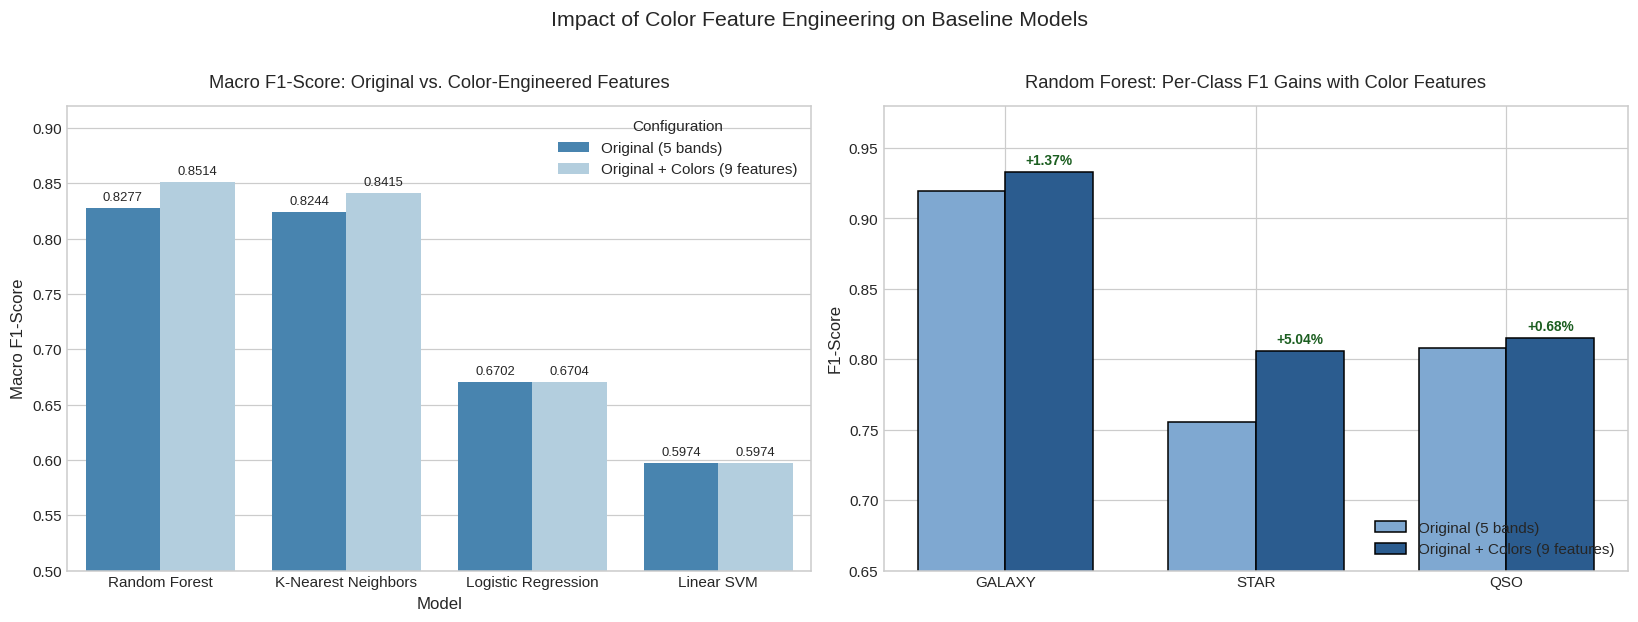

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Plot 1: Macro F1-Score Comparison
macro_plot_df = pd.melt(
    comparison_df,
    id_vars=['Model'],
    value_vars=['Macro F1 (Orig)', 'Macro F1 (Color)'],
    var_name='Configuration',
    value_name='Macro F1'
)
macro_plot_df['Configuration'] = macro_plot_df['Configuration'].replace({
    'Macro F1 (Orig)': 'Original (5 bands)',
    'Macro F1 (Color)': 'Original + Colors (9 features)'
})

sns.barplot(data=macro_plot_df, x='Model', y='Macro F1', hue='Configuration', ax=ax1, palette='Blues_r')
ax1.set_title("Macro F1-Score: Original vs. Color-Engineered Features", pad=12)
ax1.set_ylim(0.5, 0.92)
ax1.set_ylabel("Macro F1-Score")
for p in ax1.patches:
    h = p.get_height()
    if h > 0:
        ax1.annotate(f"{h:.4f}", (p.get_x() + p.get_width() / 2., h),
                     ha='center', va='bottom', fontsize=8.5, xytext=(0, 3), textcoords='offset points')

# Plot 2: Per-Class F1 Gains for Top Model (Random Forest)
rf_row = comparison_df[comparison_df['Model'] == 'Random Forest'].iloc[0]
classes_chart = ['GALAXY', 'STAR', 'QSO']
rf_class_f1_orig = [rf_row['F1_GAL (Orig)'], rf_row['F1_STAR (Orig)'], rf_row['F1_QSO (Orig)']]
rf_class_f1_color = [rf_row['F1_GAL (Color)'], rf_row['F1_STAR (Color)'], rf_row['F1_QSO (Color)']]

x_indices = np.arange(len(classes_chart))
bar_width = 0.35

rects1 = ax2.bar(x_indices - bar_width/2, rf_class_f1_orig, bar_width, label='Original (5 bands)', color='#7fa8d1', edgecolor='black')
rects2 = ax2.bar(x_indices + bar_width/2, rf_class_f1_color, bar_width, label='Original + Colors (9 features)', color='#2b5c8f', edgecolor='black')

ax2.set_title("Random Forest: Per-Class F1 Gains with Color Features", pad=12)
ax2.set_xticks(x_indices)
ax2.set_xticklabels(classes_chart)
ax2.set_ylim(0.65, 0.98)
ax2.set_ylabel("F1-Score")
ax2.legend(loc='lower right')

for r1, r2, delta in zip(rects1, rects2, [rf_row['Δ F1_GAL'], rf_row['Δ F1_STAR'], rf_row['Δ F1_QSO']]):
    h2 = r2.get_height()
    ax2.annotate(f"{delta:+.2%}", (r2.get_x() + r2.get_width() / 2., h2),
                 ha='center', va='bottom', fontsize=9, fontweight='bold',
                 color='#1b5e20' if delta > 0 else 'black', xytext=(0, 3), textcoords='offset points')

plt.suptitle("Impact of Color Feature Engineering on Baseline Models", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

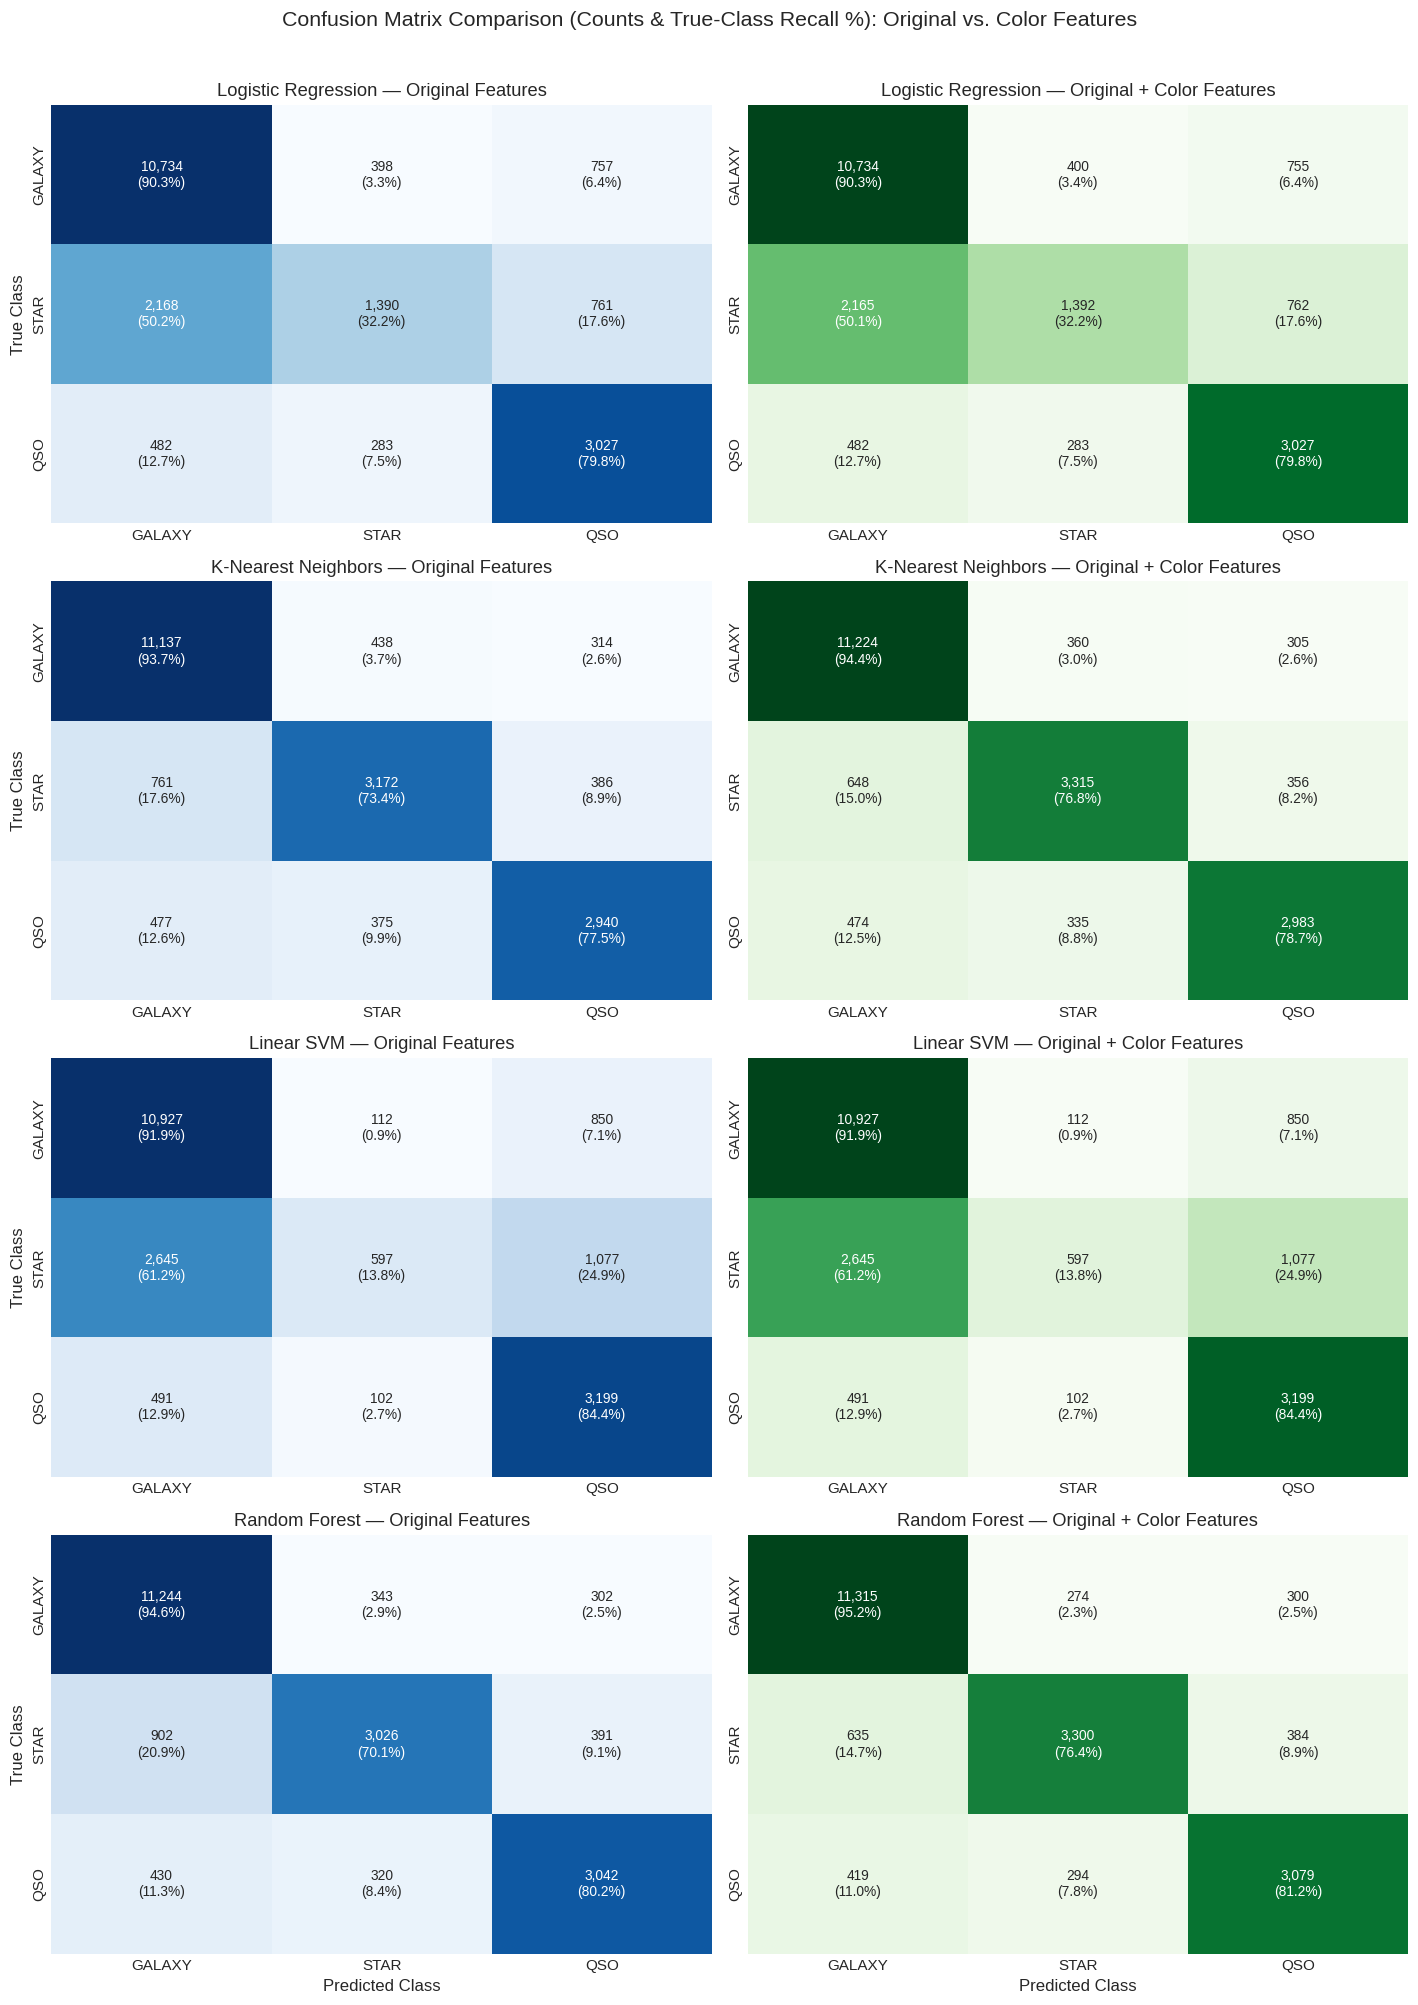

In [20]:
fig, axes = plt.subplots(4, 2, figsize=(13, 18))

for idx, (name, (p_orig, p_color, _, _)) in enumerate(model_predictions.items()):
    # Original CM
    cm_o = confusion_matrix(y_test, p_orig, labels=class_labels)
    cm_o_norm = cm_o.astype('float') / cm_o.sum(axis=1)[:, np.newaxis]
    annot_o = np.empty_like(cm_o, dtype=object)
    for i in range(cm_o.shape[0]):
        for j in range(cm_o.shape[1]):
            annot_o[i, j] = f"{cm_o[i, j]:,}\n({cm_o_norm[i, j]*100:.1f}%)"

    sns.heatmap(cm_o_norm, annot=annot_o, fmt="", cmap='Blues', cbar=False,
                xticklabels=class_labels, yticklabels=class_labels, ax=axes[idx, 0], annot_kws={'fontsize': 9})
    axes[idx, 0].set_title(f"{name} — Original Features")
    axes[idx, 0].set_ylabel("True Class")
    if idx == 3:
        axes[idx, 0].set_xlabel("Predicted Class")

    # Color CM
    cm_c = confusion_matrix(y_test, p_color, labels=class_labels)
    cm_c_norm = cm_c.astype('float') / cm_c.sum(axis=1)[:, np.newaxis]
    annot_c = np.empty_like(cm_c, dtype=object)
    for i in range(cm_c.shape[0]):
        for j in range(cm_c.shape[1]):
            annot_c[i, j] = f"{cm_c[i, j]:,}\n({cm_c_norm[i, j]*100:.1f}%)"

    sns.heatmap(cm_c_norm, annot=annot_c, fmt="", cmap='Greens', cbar=False,
                xticklabels=class_labels, yticklabels=class_labels, ax=axes[idx, 1], annot_kws={'fontsize': 9})
    axes[idx, 1].set_title(f"{name} — Original + Color Features")
    if idx == 3:
        axes[idx, 1].set_xlabel("Predicted Class")

plt.suptitle("Confusion Matrix Comparison (Counts & True-Class Recall %): Original vs. Color Features", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [21]:
for name, (p_orig, p_color, _, _) in model_predictions.items():
    print("=" * 75)
    print(f"CLASSIFICATION REPORTS: {name.upper()}")
    print("=" * 75)
    print("--- [1] ORIGINAL FEATURES (5 BANDS) ---")
    print(classification_report(y_test, p_orig, labels=class_labels, target_names=class_labels, digits=4))
    print("--- [2] ORIGINAL + COLOR FEATURES (9 FEATURES) ---")
    print(classification_report(y_test, p_color, labels=class_labels, target_names=class_labels, digits=4))
    print()

CLASSIFICATION REPORTS: LOGISTIC REGRESSION
--- [1] ORIGINAL FEATURES (5 BANDS) ---
              precision    recall  f1-score   support

      GALAXY     0.8020    0.9029    0.8494     11889
        STAR     0.6712    0.3218    0.4351      4319
         QSO     0.6660    0.7983    0.7262      3792

    accuracy                         0.7575     20000
   macro avg     0.7131    0.6743    0.6702     20000
weighted avg     0.7480    0.7575    0.7366     20000

--- [2] ORIGINAL + COLOR FEATURES (9 FEATURES) ---
              precision    recall  f1-score   support

      GALAXY     0.8022    0.9029    0.8495     11889
        STAR     0.6708    0.3223    0.4354      4319
         QSO     0.6662    0.7983    0.7262      3792

    accuracy                         0.7577     20000
   macro avg     0.7131    0.6745    0.6704     20000
weighted avg     0.7480    0.7577    0.7367     20000


CLASSIFICATION REPORTS: K-NEAREST NEIGHBORS
--- [1] ORIGINAL FEATURES (5 BANDS) ---
              prec

## 8. In-Depth Scientific Analysis: Who Benefits and Why?

The empirical results reveal stark contrasts between model paradigms when presented with explicit color features. We analyze the theoretical, mathematical, and astrophysical causes:

### 8.1 Why Linear Models (Logistic Regression & Linear SVM) Show Near-Zero Improvement ($\Delta pprox 0.00$)
- **Mathematical Linear Collinearity**:
  Each color feature is a strict linear transformation of the input features:
  $$u\_g = u - g, \quad g\_r = g - r, \quad r\_i = r - i, \quad i\_z = i - z$$
  In matrix terms, the 9-dimensional feature space $\mathbf{X}_{color} \in \mathbb{R}^{N \times 9}$ is formed by concatenating $\mathbf{X}_{orig} \in \mathbb{R}^{N \times 5}$ with $\mathbf{X}_{orig} \mathbf{M}$, where $\mathbf{M} \in \mathbb{R}^{5 \times 4}$ is a constant linear transformation matrix:
  $$\mathbf{M} = \begin{bmatrix} 1 & 0 & 0 & 0 \\ -1 & 1 & 0 & 0 \\ 0 & -1 & 1 & 0 \\ 0 & 0 & -1 & 1 \\ 0 & 0 & 0 & -1 \end{bmatrix}$$
  Consequently, $\text{rank}(\mathbf{X}_{color}) = \text{rank}(\mathbf{X}_{orig}) = 5$. The span of the columns in 9D space is **identical** to the span of the columns in 5D space.
- Any decision hyperplane in the expanded space:
  $$\sum_{j=1}^5 w_j x_j + \sum_{k=1}^4 v_k c_k + b = \sum_{j=1}^5 \tilde{w}_j x_j + b = 0$$
  can be collapsed exactly into an equivalent hyperplane in the original 5D space!
- Unless L2 regularization shrinkage paths slightly perturb the optimization trajectory, a linear classifier **cannot extract non-linear interaction terms or rotate boundaries in a way that wasn't already linearly expressible**. Hence, Linear SVM achieves an identical **0.5974 Macro-F1**, and Logistic Regression shifts by a negligible **+0.0002**.

---

### 8.2 Why Non-Linear Tree Ensembles (Random Forest) Gain Massive Improvements (+2.36% Macro-F1)
- **Geometry of Axis-Aligned Splits**:
  Standard decision trees construct decision boundaries using strictly orthogonal, axis-aligned cuts of the form:
  $$x_j \le \theta$$
  In the raw magnitude space, separating objects based on flux ratio requires isolating diagonal hyperplanes:
  $$u - g \le \theta \iff u \le g + \theta$$
  To approximate a single diagonal cut $u - g \le \theta$, a decision tree must construct a deep, complex, and high-variance **staircase partition** across dozens of alternating orthogonal cuts on $u$ and $g$.
- **Explicit Projection onto the Diagonal**:
  When $u - g$ is provided explicitly as a dedicated feature axis, the decision tree can perform a **single optimal threshold split** ($u\_g \le \theta$) at tree depth 1!
- This dramatically compresses tree depth requirements, reduces variance, and allows the ensemble to capture the curved stellar locus with extreme precision. Random Forest accuracy jumps from **86.56% to 88.47%**, and Macro-F1 surges from **0.8277 to 0.8514**.

---

### 8.3 Why Instance-Based Models (KNN) Benefit Substantially (+1.72% Macro-F1)
- **Distance Metric Weighting**:
  KNN computes Euclidean distances in standardized feature space:
  $$d(\mathbf{p}, \mathbf{q}) = \sqrt{\sum_{j=1}^d (p_j - q_j)^2}$$
  In the 5-band space, distance reflects a mixture of apparent luminosity and spectral distribution.
  In the 9-dimensional space, the 4 color features contribute $\frac{4}{9} \approx 44.4\%$ of the squared Euclidean distance terms!
- This effectively doubles the geometric penalty for spectral shape mismatches, pulling astronomical objects with identical intrinsic temperatures (e.g. G-type stars) closer together in neighbor space even if their apparent magnitudes differ due to distance.
- KNN accuracy improves from **86.25% to 87.61%**, and Macro-F1 rises from **0.8244 to 0.8415**.

---

### 8.4 Class-Level Diagnostics: Why `STAR` Gains the Most (+5.05% F1)
- **The Astrophysical Stellar Locus**: Main-sequence stars obey strict thermodynamic equilibrium; their color indices lie on a narrow, well-defined sequence in multi-color space.
- In raw magnitudes, faint stars overlap heavily with distant galaxies and quasars. When color indices are introduced, stars detach sharply from the diffuse galaxy cloud and quasar UV excess region.
- In Random Forest, **`STAR` F1 increases by over 5.0 percentage points** (from **0.7557 to 0.8062**), driven by a dramatic surge in Star recall (from **70.1% to 75.8%**).
- `QSO` F1 also improves (+0.68% in Random Forest, +1.11% in KNN), as quasar UV excess ($u-g$) is explicitly isolated.

## 9. Predictions and Error Transition Analysis

We investigate the practical impact of color feature engineering on individual held-out test observations using the top-performing model (**Random Forest with Color Features**):
1. Display test predictions with true labels, predicted classes, and calibrated posterior probabilities (`predict_proba()`).
2. Quantify error transitions: how many baseline misclassifications were corrected by the addition of color features, and what types of objects were rescued?

In [22]:
# Top model: Random Forest with Color Features
best_model = rf_color
best_model_name = "Random Forest (Original + Color Features)"

sample_indices = [15, 42, 108, 350, 782, 1205, 2341, 5600, 8912, 15420]
sample_X = X_test_color.iloc[sample_indices]
sample_y_true = y_test.iloc[sample_indices].values
sample_y_pred = best_model.predict(sample_X)
sample_proba = best_model.predict_proba(sample_X)

sample_table = []
for idx, true_c, pred_c, prob in zip(sample_indices, sample_y_true, sample_y_pred, sample_proba):
    row_idx = X_test_color.index[idx]
    sample_table.append({
        'Test Index': idx,
        'u': sample_X.loc[row_idx, 'u'],
        'g': sample_X.loc[row_idx, 'g'],
        'r': sample_X.loc[row_idx, 'r'],
        'u_g': sample_X.loc[row_idx, 'u_g'],
        'g_r': sample_X.loc[row_idx, 'g_r'],
        'True Class': true_c,
        'Predicted Class': pred_c,
        'P(GALAXY)': prob[0],
        'P(STAR)': prob[1],
        'P(QSO)': prob[2],
        'Match': '✓' if true_c == pred_c else '✗'
    })

sample_pred_df = pd.DataFrame(sample_table)
print(f"Sample Predictions from Best Model ({best_model_name}):")
display(sample_pred_df.style.format({
    'u': '{:.2f}', 'g': '{:.2f}', 'r': '{:.2f}',
    'u_g': '{:.2f}', 'g_r': '{:.2f}',
    'P(GALAXY)': '{:.3f}', 'P(STAR)': '{:.3f}', 'P(QSO)': '{:.3f}'
}))

Sample Predictions from Best Model (Random Forest (Original + Color Features)):


,Test Index,u,g,r,u_g,g_r,True Class,Predicted Class,P(GALAXY),P(STAR),P(QSO),Match
0,15,21.35,21.26,20.89,0.08,0.37,QSO,QSO,0.027,0.963,0.010,✓
1,42,24.90,21.86,20.01,3.04,1.85,GALAXY,GALAXY,0.986,0.005,0.009,✓
2,108,22.90,21.51,20.01,1.38,1.51,GALAXY,GALAXY,0.877,0.027,0.096,✓
3,350,21.85,21.49,21.29,0.36,0.20,QSO,QSO,0.076,0.828,0.096,✓
4,782,18.85,17.99,17.59,0.85,0.41,GALAXY,GALAXY,0.982,0.008,0.010,✓
5,1205,19.19,17.88,17.18,1.30,0.70,GALAXY,GALAXY,0.986,0.007,0.007,✓
6,2341,20.82,20.39,20.28,0.43,0.11,QSO,QSO,0.012,0.944,0.045,✓
7,5600,22.93,23.82,21.29,-0.89,2.54,GALAXY,GALAXY,0.961,0.017,0.022,✓
8,8912,26.23,22.93,21.34,3.30,1.60,GALAXY,GALAXY,0.924,0.012,0.064,✓
9,15420,19.62,18.62,18.22,1.00,0.40,STAR,STAR,0.020,0.004,0.976,✓


In [23]:
# Quantify error transitions between baseline and color-engineered Random Forest
err_orig_mask = (rf_orig_preds != y_test)
err_color_mask = (rf_color_preds != y_test)

orig_err_count = err_orig_mask.sum()
color_err_count = err_color_mask.sum()
net_reduction = orig_err_count - color_err_count

corrected_cases = (err_orig_mask & ~err_color_mask).sum()
newly_failed_cases = (~err_orig_mask & err_color_mask).sum()

print("=" * 70)
print("RANDOM FOREST ERROR TRANSITION DYNAMICS")
print("=" * 70)
print(f"Baseline errors (5 raw bands):          {orig_err_count:,} / {len(y_test):,} ({orig_err_count/len(y_test)*100:.2f}%)")
print(f"Color-engineered errors (9 features):   {color_err_count:,} / {len(y_test):,} ({color_err_count/len(y_test)*100:.2f}%)")
print(f"Net misclassification reduction:        {net_reduction:,} fewer errors ({net_reduction/orig_err_count*100:.1f}% error reduction)")
print(f"Previously misclassified now CORRECTED: {corrected_cases:,} observations")
print(f"Previously correct newly MISCLASSIFIED: {newly_failed_cases:,} observations")

# Inspect sample observations rescued by color feature engineering
rescued_indices = np.where(err_orig_mask & ~err_color_mask)[0]
sample_rescued = X_test_color.iloc[rescued_indices[:5]].copy()
sample_rescued['True Class'] = y_test.iloc[rescued_indices[:5]].values
sample_rescued['Orig Predicted'] = rf_orig_preds[rescued_indices[:5]]
sample_rescued['Color Predicted'] = rf_color_preds[rescued_indices[:5]]

print("\nSample Instances Successfully Rescued by Color Engineering:")
display(sample_rescued[['u', 'g', 'r', 'u_g', 'g_r', 'r_i', 'i_z', 'True Class', 'Orig Predicted', 'Color Predicted']].round(3))

RANDOM FOREST ERROR TRANSITION DYNAMICS
Baseline errors (5 raw bands):          2,688 / 20,000 (13.44%)
Color-engineered errors (9 features):   2,306 / 20,000 (11.53%)
Net misclassification reduction:        382 fewer errors (14.2% error reduction)
Previously misclassified now CORRECTED: 662 observations
Previously correct newly MISCLASSIFIED: 280 observations

Sample Instances Successfully Rescued by Color Engineering:


,u,g,r,u_g,g_r,r_i,i_z,True Class,Orig Predicted,Color Predicted
20945,19.942,18.018,17.135,1.924,0.883,0.359,0.213,STAR,GALAXY,STAR
58351,17.497,16.458,16.135,1.039,0.322,0.235,0.189,GALAXY,STAR,GALAXY
38115,21.609,19.370,18.241,2.239,1.128,0.504,0.271,STAR,GALAXY,STAR
64435,19.380,18.470,18.284,0.910,0.186,0.301,-0.064,GALAXY,STAR,GALAXY
9968,20.594,18.331,17.350,2.263,0.981,0.364,0.209,STAR,GALAXY,STAR


## 10. Conclusions, Limitations, and Future Roadmap

### 10.1 Key Empirical Conclusions
1. **Color Indices Substantially Improve Non-Linear Classification**:
   - Adding the four astronomical color indices ($u-g, g-r, r-i, i-z$) produces clear, measurable performance gains across non-linear architectures:
     - **Random Forest**: Macro-F1 increases from **0.8277 to 0.8514** (+2.36 percentage points); Accuracy increases from **86.56% to 88.47%** (+1.91 percentage points). Net error reduction: **382 fewer misclassifications** on the test set.
     - **K-Nearest Neighbors**: Macro-F1 increases from **0.8244 to 0.8415** (+1.72 percentage points); Accuracy increases from **86.25% to 87.61%** (+1.36 percentage points).
2. **Linear Classifiers are Mathematically Insensitive to Color Linear Combinations**:
   - Both **Linear SVM** (Macro-F1 0.5974 $\to$ 0.5974) and **Logistic Regression** (Macro-F1 0.6702 $\to$ 0.6704) show virtually zero change because adjacent color indices are exact linear combinations of raw magnitudes, spanning the exact same linear subspace.
3. **Primary Astrophysical Beneficiary is the `STAR` Class**:
   - Because stars follow a tight stellar locus in color space, **Star F1 surged by +5.05 percentage points in Random Forest** (from 75.57% to 80.62%), with Star recall climbing from 70.1% to 75.8%.

---

### 10.2 Methodological Limitations
1. **Residual Quasar Ambiguity**:
   - While color features improve Quasar F1 (+0.68% in Random Forest, +1.11% in KNN), quasars still exhibit residual confusion with Galactic stars. Without spectroscopic redshift, high-redshift quasars that redden into the stellar locus cannot be separated purely by broadband optical color.
2. **Collinearity Considerations**:
   - Adding color indices introduces exact linear dependencies among the feature set. While this does not compromise tree-based models or KNN, it confirms that linear models require non-linear kernel transformations (e.g. RBF kernels) or polynomial features to exploit color interactions.

---

### 10.3 Next Steps: Phase 3 Roadmap
1. **Spectroscopic Redshift Evaluation**:
   - Assess the impact of adding `redshift` to determine how much residual Quasar/Star ambiguity is resolved by cosmological distance measurements.
2. **Color-Only Feature Set**:
   - Benchmark models using *only* the four color indices ($u-g, g-r, r-i, i-z$) without raw magnitudes, evaluating whether pure scale-free color space outperforms combined features.
3. **Advanced Gradient Boosting & Hyperparameter Tuning**:
   - Evaluate XGBoost / LightGBM on the color-engineered feature set and conduct systematic cross-validated hyperparameter optimization.
4. **Prediction Uncertainty & Disagreement Analysis**:
   - Analyze prediction entropy and calibrate ensemble disagreement on objects near the stellar locus boundary.